In [2]:
import matplotlib.pyplot as plt
from math import floor
import numpy as np
import pandas as pd
from keras.callbacks import ModelCheckpoint
from keras.layers import Dense, InputLayer, LSTM
from keras.losses import MeanSquaredError
from keras.metrics import RootMeanSquaredError
from keras.models import load_model, Sequential
import seaborn as sns
sns.set_theme()

# The dataset

In [3]:
df = pd.read_csv('../data/datasets/daily_weather_data.csv')
df.head()

,date,country,city,Latitude,Longitude,tavg,tmin,tmax,wdir,wspd,pres
0,21-07-2018,Abkhazia,Sukhumi,43.001525,41.023415,23.4,20.9,25.5,329.0,9.3,1009.6
1,22-07-2018,Abkhazia,Sukhumi,43.001525,41.023415,23.5,21.0,25.7,337.0,9.4,1010.0
2,23-07-2018,Abkhazia,Sukhumi,43.001525,41.023415,23.5,21.1,25.5,41.0,8.2,1007.7
3,24-07-2018,Abkhazia,Sukhumi,43.001525,41.023415,24.3,20.8,27.1,10.0,9.3,1004.4
4,25-07-2018,Abkhazia,Sukhumi,43.001525,41.023415,26.5,22.7,30.0,9.0,9.7,1002.0


# Selecting data from Netherlands

In [4]:
df = df[df['country'] == 'Netherlands']['wspd']
df.reset_index(drop=True, inplace=True)
df.head()

0    28.2
1    23.3
2    48.6
3    31.5
4    21.3
Name: wspd, dtype: float64

In [5]:
df.shape

(1745,)

## Removing NaN values

In [6]:
df.isnull().sum()

5

In [7]:
df.dropna(inplace=True)

# X and y data

In [8]:
forecasting_lag = 10

In [9]:
def df_to_X_y(df, lag):
    array = df.to_numpy()
    X = []
    y = []
    for i in range(len(array) - lag):
        row = [[a] for a in array[i:i+lag]]
        X.append(row)
        label = array[i+lag]
        y.append(label)
    return np.array(X), np.array(y)

In [10]:
X, y = df_to_X_y(df, forecasting_lag)
X.shape, y.shape

((1730, 10, 1), (1730,))

In [11]:
train_size = round(len(X) * 0.8)
test_size = round((len(X) - train_size) / 2)
test_size = round(test_size, 2)
val_size = floor((len(X) - train_size) / 2)
print(f'Train size: {train_size}')
print(f'Test size: {test_size}')
print(f'Validation size: {val_size}')

Train size: 1384
Test size: 173
Validation size: 173


In [12]:
X_train, y_train = X[:1388], y[:1388]
X_valid, y_valid = X[1388:1562], y[1388:1562]
X_test, y_test = X[1562:], y[1562:]

In [13]:
X_train.shape, y_train.shape

((1388, 10, 1), (1388,))

In [14]:
X_test.shape, y_test.shape

((168, 10, 1), (168,))

In [15]:
X_valid.shape, y_valid.shape

((174, 10, 1), (174,))

# LSTM

In [17]:
model = Sequential()
#model.add(InputLayer(input_shape=(forecasting_lag, 1)))
model.add(InputLayer(shape=(forecasting_lag, 1)))
model.add(LSTM(units=75))
model.add(Dense(units=1, activation='linear'))

In [18]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 75)             │        23,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            76 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,176 (90.53 KB)

 Trainable params: 23,176 (90.53 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
model_checkpoint = ModelCheckpoint('LSTM_model.keras', save_best_only=True)

In [20]:
model.compile(loss=MeanSquaredError(), optimizer='adam', metrics=[RootMeanSquaredError()])

In [21]:
train_epochs = 80

In [22]:
epochs = model.fit(X_train, y_train, epochs=train_epochs, validation_data=(X_valid, y_valid), callbacks=[model_checkpoint])

Epoch 1/80
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - loss: 317.2139 - root_mean_squared_error: 17.7645 - val_loss: 212.0214 - val_root_mean_squared_error: 14.5610
Epoch 2/80
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 112.9210 - root_mean_squared_error: 10.6168 - val_loss: 113.7341 - val_root_mean_squared_error: 10.6646
Epoch 3/80
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 67.0493 - root_mean_squared_error: 8.1847 - val_loss: 96.9946 - val_root_mean_squared_error: 9.8486
Epoch 4/80
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 63.1576 - root_mean_squared_error: 7.9405 - val_loss: 92.6061 - val_root_mean_squared_error: 9.6232
Epoch 5/80
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 57.1950 - root_mean_squared_error: 7.5575 - val_loss: 88.7830 - val_root_mean_squared_error: 9.4225
Epoch 6/80
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 59.0041 - root_mean_squared_error: 7.6762 - val_loss: 84.0719 - val_root_mean_squared_error: 9.1691
Epoch 7/80
44/44 ━━━━━━━━━━━━━━━━━━━━ 

In [23]:
model = load_model('LSTM_model.keras')

## Loss and Validation Loss

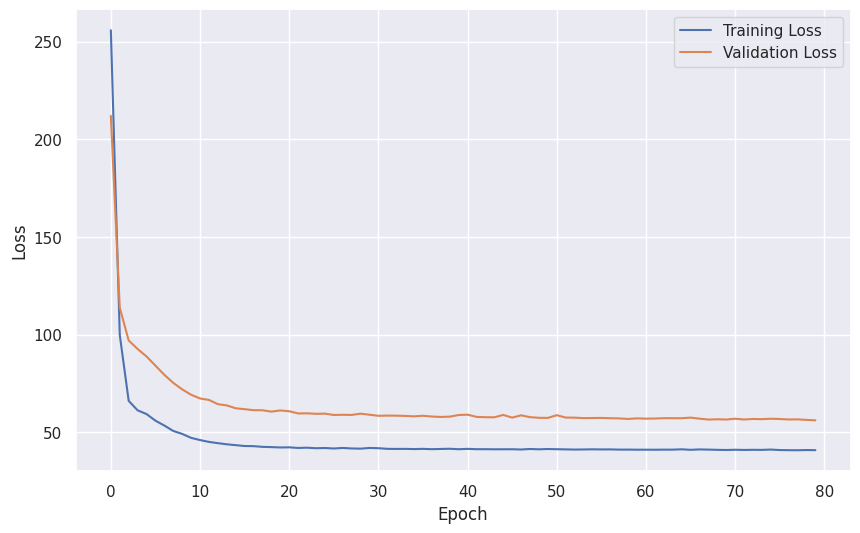

In [24]:
loss_figure = plt.figure(figsize=(10, 6))
plt.plot(epochs.history['loss'], label='Training Loss')
plt.plot(epochs.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

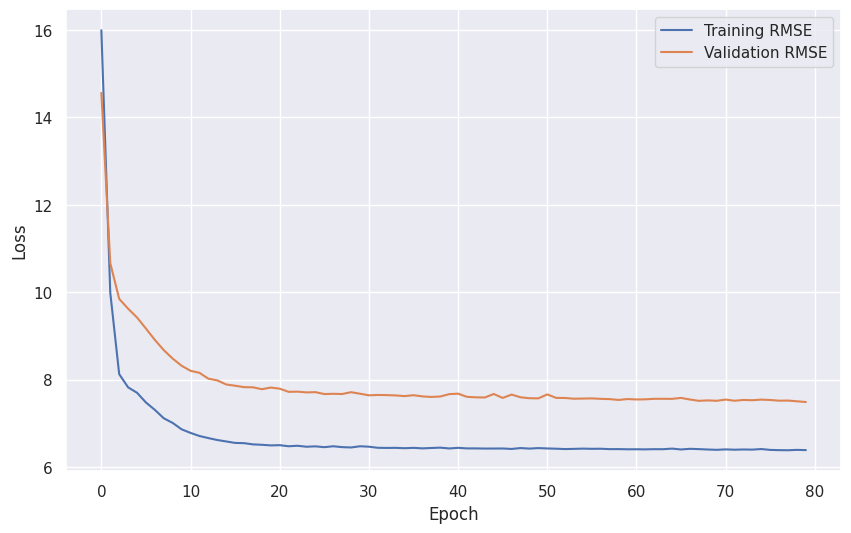

In [25]:
rmse_figure = plt.figure(figsize=(10, 6))
plt.plot(epochs.history['root_mean_squared_error'], label='Training RMSE')
plt.plot(epochs.history['val_root_mean_squared_error'], label='Validation RMSE')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

## Predictions

In [26]:
train_predict = model.predict(X_train)

44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step


In [27]:
test_predict = model.predict(X_test)

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 


# Results

## Train Results

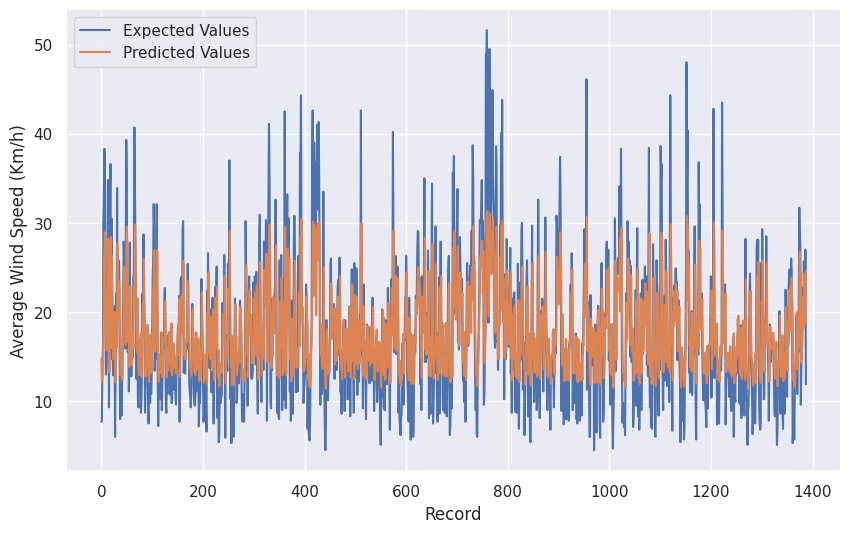

In [28]:
train_figure = plt.figure(figsize=(10, 6))
plt.plot(y_train, label='Expected Values')
plt.plot(train_predict, label='Predicted Values')
plt.xlabel('Record')
plt.ylabel('Average Wind Speed (Km/h)')
plt.legend()
plt.show()

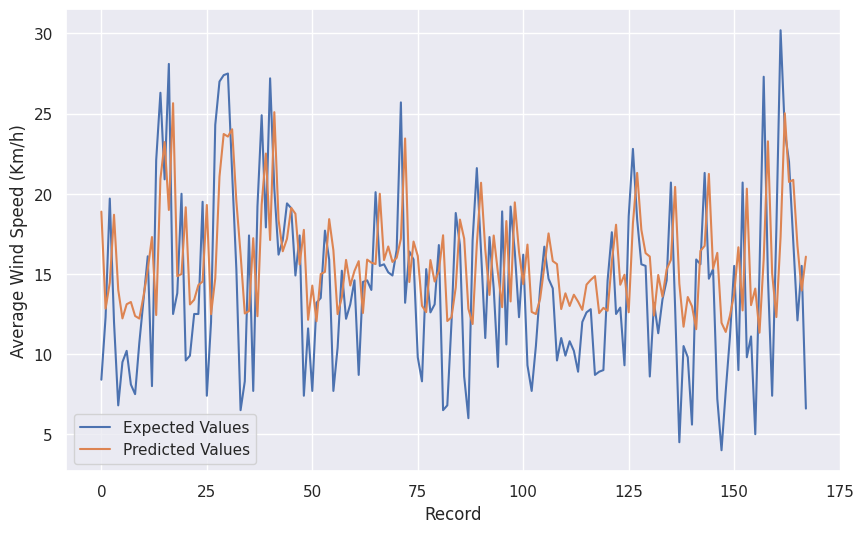

In [30]:
test_figure = plt.figure(figsize=(10, 6))
plt.plot(y_test, label='Expected Values')
plt.plot(test_predict, label='Predicted Values')
plt.xlabel('Record')
plt.ylabel('Average Wind Speed (Km/h)')
plt.legend()
plt.show()